# K-MEANS

- Un algoritmo de aprendizaje no supervisado de la categoría de **métodos particionales**

- Un cluster se resume mediante un prototipo

--------

## ¿Cómo funciona?

1. Inicializa K centroides (uno para cada cluster)

$$
c_k = \frac{1}{C_k} \sum_{x^{(i)} \in C_k } x^{(i)} 
$$

2. Le asigna el cluster más cercano a cada punto

$$
z^{(i)} = \text{arg mín}_k \lVert x^{(i)} - c_k \rVert _2^2
$$

3. En cada cluster, calcula las medias de sus puntos para actualizar el centroide

$$
c_k = \frac{1}{|c_k|} \sum_{x^{(i)} \in C_k } x^{(i)} 
$$

4. Si aún no converge (maximo de iteraciones o cuando las particiones dejan de cambiar), pasar a 2

-------

## ¿Por qué k-means?

- K es un hiperparámetro que definimos nosotros. Depende del problema y las necesidades del negocio / cliente.
- Means porque el centroide es el promedio de sus instancias
- Podemos usar el método del codo para estimar cual es el "k ideal" si no sabemos cuántas k definir de antemano



-----------

### SSE (Sum of Squared Errors)

Como su criterio de optimización, el algoritmo alterna asignación y actualización buscando reducir la **SSE**:

$$
J_{KM} = \sum_{k=1}^{K} \sum_{x^{(i)} \in C_k} \lVert x^{(i)} - c_k \rVert _2^2
$$

- También se le conoce como **inercia** (*inertia*)
- El procedimiento converge en un mínimo local, por ello la inicialización puede afectar la solución obtenida
- El centroide se define al inicio de manera aleatoria

------

# Implementación en código

- Usaremos la clase KMeans de Scikit-Learn
- Como es un algoritmo basado en instancias, es sensible si los datos están en diferentes escalas (ej. tener millones en una característica y decenas en otra).
    - Por lo que usaremos MinMaxScaler para escalar cada dato:

    $$
    X_i^{*} = \frac{X_i - min(X)}{max(X) - min(X)}
    $$



In [68]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
plt.style.use('dark_background') # poner modo oscuro los plots

RAND_STATE = 42 # para reproducibilidad, se usará 42 como random state
K = 3   

---------

## Nuestros datos

In [69]:
df = pd.DataFrame({
    "x_1":[0, 1, 0, 4, 6, 8, 10, 1, 1, 1,3 , 5],
    "x_2":[0, 0, 1, 0, 0, 1, 2, 5, 7, 9, 9, 9 ]
})

df

,x_1,x_2
0,0,0
1,1,0
2,0,1
3,4,0
4,6,0
5,8,1
6,10,2
7,1,5
8,1,7
9,1,9


--------

## Visualmente

Text(0, 0.5, 'x_2')

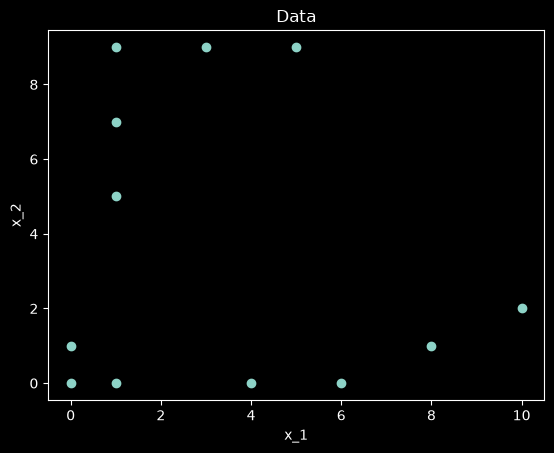

In [70]:
plt.scatter(df['x_1'], df['x_2'])
plt.title("Data")
plt.xlabel("x_1")
plt.ylabel("x_2")

-----------

### Escalamos nuestros datos

In [71]:
escalador = MinMaxScaler().fit(df.values) # valores escalados

# guardar los valores escalados
df = pd.DataFrame(
    escalador.transform(df.values),
    columns=['x_1', 'x_2']
)

df

,x_1,x_2
0,0.0,0.000000
1,0.1,0.000000
2,0.0,0.111111
3,0.4,0.000000
4,0.6,0.000000
5,0.8,0.111111
6,1.0,0.222222
7,0.1,0.555556
8,0.1,0.777778
9,0.1,1.000000


---------


### Creación del modelo


In [72]:
# generar el modelo
model = KMeans(n_clusters=K, random_state=RAND_STATE).fit(df.values)

# ver los clusters (0, 1, 2, ...) de cada uno de los datos
model.labels_

array([2, 2, 2, 0, 0, 0, 0, 1, 1, 1, 1, 1], dtype=int32)

In [73]:
# agregar columna de la etiqueta de cluster al df
df['cluster'] = model.labels_

df.head()

,x_1,x_2,cluster
0,0.0,0.000000,2
1,0.1,0.000000,2
2,0.0,0.111111,2
3,0.4,0.000000,0
4,0.6,0.000000,0


---------

### Cosas Importantes

- La inercia (SSE) se calcula con la distancia al cuadrado de cada uno de los puntos hacia el centroide. Suma todas las distancias y las pondera por el número de instancias que se tienen para un cluster dado
<!-- Al ^2 porque le da más importancia a los puntos que se encuentran más lejos y menor importancia a los puntos que se encuentran muy cerca. -->

- las metricas siempre deben de estar asociadas al negocio, no siempre que sea mejor es bueno significa que la inercia sea baja

- lo deseable es tener un valor k bajo y un valor de inercia pequeño

----------

### Cosas a saber sobre mi modelo

- **n_clusters** el numero de clusters
- **cluster_centers_** los centroides
- **inercia o SSE**: qué tan bien conformados están nuestros clusters

In [74]:
print(model.n_clusters)

print('\n',model.cluster_centers_)

print('\n', model.inertia_)


3

 [[0.7        0.08333333]
 [0.22       0.86666667]
 [0.03333333 0.03703704]]

 0.5348724279835391


---------

### Viendo los clusters

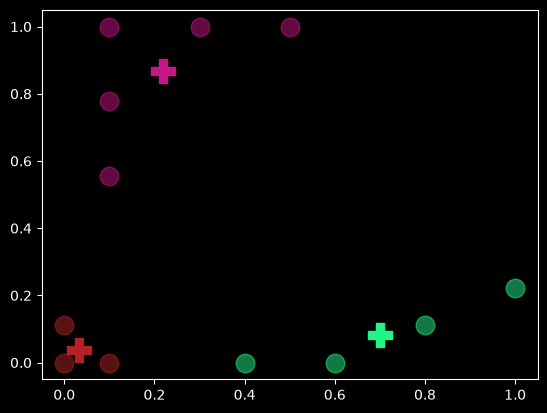

In [75]:
colors = ['#22F588','#C71585','#B22222']

for clus in range(model.n_clusters):
    plt.scatter(
        df[df['cluster'] == clus]['x_1'],
        df[df['cluster'] == clus]['x_2'],
        s=180, color=colors[clus], alpha=0.5
    )

    plt.scatter(model.cluster_centers_[clus][0],
                model.cluster_centers_[clus][1],
                marker='P', s=280, color=colors[clus])

------


## Método del codo

- Para encontrar el numero "ideal" de clusters, se puede usar el método del codo.
- Simplemente visualmente escogemos del "brazo formado por el grafico de las inercias". 
- El "codo" es el punto dónde hay mayor cambio de inercia.
- La "desventaja" es que puede ser un poco ambiguo porque el k inicial podría ser uno a la derecha o una a la izquierda
- Además, el número de clusters (K) depende más del problema y las necesidades del negocio

-------

## Método del codo

In [76]:
inercias = []

# calcular las inercias para cada 'k'
x = range(2, 10)
for k in x:
    model = KMeans(n_clusters=k).fit(df.values)
    inercias.append(model.inertia_)

print(inercias)

[3.765740740740741, 0.5348724279835391, 0.34709465020576136, 0.20781893004115226, 0.13958847736625515, 0.11958847736625511, 0.05489711934156381, 0.034897119341563795]


-------

Text(0, 0.5, 'inercias')

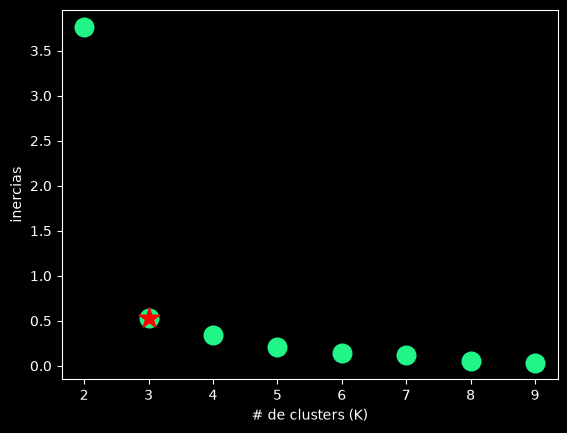

In [77]:
plt.scatter(x, inercias, s=180, color="#22F588")

# destacar al mejor k
plt.scatter(x[1], inercias[1], marker='*', s=240, color="red")

plt.xlabel("# de clusters (K)")
plt.ylabel("inercias")

---------

# ¿Cómo funciona la predicción de un nuevo dato?

En **K-Means**, la predicción de un nuevo dato se basa en la geometría de los centroides aprendidos durante la fase de entrenamiento.


Cuando llega un nuevo dato ($\mathbf{x}_{\text{nuevo}}$):
1. **Cálculo de distancias:** El modelo mide la distancia euclidiana entre $\mathbf{x}_{\text{nuevo}}$ y cada uno de los $K$ centroides.
2. **Asignación por cercanía:** Asigna el nuevo dato al grupo cuyo centroide esté a la menor distancia:
   
   $$z_{\text{nuevo}} = argmin_k \|\mathbf{x}_{\text{nuevo}} - \mathbf{c}_k\|_2^2$$
   
   Geométricamente, esto equivale a identificar en qué celda del **teselado de Voronoi** (fronteras de decisión formadas por los centroides) cae el nuevo punto.


---------


## Diferencia entre .predict(X_new) y .transform(X_new)

En bibliotecas como *Scikit-Learn*, ambos métodos aceptan un nuevo conjunto de datos X_new, pero devuelven información conceptualmente distinta:

#### .predict(X_new) — Agrupamiento Rígido
* **Qué hace:** Realiza la asignación categórica directa devolviendo el **índice del cluster más cercano** ($0, 1, \dots, K-1$) para cada observación.
* **Forma de la salida (*Shape*):** Arreglo unidimensional de enteros de tamaño (N_muestras,).
* **Uso típico:** Asignar una categoría o etiqueta final a las nuevas observaciones (por ejemplo, determinar a qué segmento pertenece un nuevo cliente).


------


#### .transform(X_new) — Agrupamiento Suave
* **Qué hace:** No asigna una sola categoría; en su lugar, calcula y devuelve la **distancia euclidiana exacta desde cada  muestra hasta cada uno de los $K$ centroides**.
* **Forma de la salida (*Shape*):** Matriz bidimensional de números reales de tamaño (N_muestras, K).
* **Uso típico:**
  * **Clustering suave / Similitud:** Permite evaluar qué tan cerca o lejos está un dato de todos los grupos al mismo tiempo, midiendo incertidumbre o grado de pertenencia.
  * **Ingeniería de características (*Feature Engineering*):** Transforma un conjunto de datos original de $D$ dimensiones a un nuevo espacio no lineal de $K$ dimensiones. Estas distancias a los centroides se pueden usar como nuevas entradas (*features*) para entrenar clasificadores supervisados como la Regresión Logística.



-------


### Tabla Comparativa

| Rubro | **.predict(X_new)** | **.transform(X_new)** |
| :--- | :--- | :--- |
| **Tipo de salida** | Enteros, como `0`, `1`, `2`, etc. | Flotantes continuos, como `[[2.81, 0.33, 2.90]]` |
| **Dimensión** | `(N,)` | `(N, K)` |
| **Significado** | Índice del centroide más cercano. | Distancia euclidiana a cada centroide $k$. |
| **Propósito principal** | Clasificar o etiquetar datos en un grupo. | *Soft clustering*, medición de distancias y extracción de características. |


------

## Referencias:

- https://www.youtube.com/watch?v=mICySHB0fh4
- Hands-on Machine Learning with Scikit-Learn, Keras & TensorFlow. Chapter 9: Unsupervised Learning Techniques


## Para revisar pronto:
- k-medoids
- k-medians
- bisecting k-means